- https://medium.com/neo4j/entity-linking-and-relationship-extraction-with-relik-in-llamaindex-ca18892c169f (relik + llamaindex + neo4j)

In [ ]:
import os
import json
from typing import List, Dict, TypedDict
from pydantic import BaseModel
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from langchain_ollama import ChatOllama

LLM_MODEL_NAME="jaro-jm/llm:latest"
# LLM_MODEL_NAME="SpeakLeash/bielik-11b-v2.3-instruct:Q8_0"
os.environ["HSA_OVERRIDE_GFX_VERSION"]="11.0.0"

llm_text = ChatOllama(model=LLM_MODEL_NAME, temperature=0, reasoning=False, num_ctx=10000, num_predict=5000)

text = """Donald Trump od początku traktował konflikt w Ukrainie jako nieswoją wojnę. Nie miał cierpliwości ani zrozumienia dla ukraińskich racji. Błędnie zakładał też, że zdoła oderwać Rosję od sojuszu z Chinami. Tymczasem oba kraje mocno zacieśniły współpracę gospodarczą, a Chiny dostarczają dziś Rosjanom maszyny i technologie, na które monopol miał kiedyś Zachód. Moskwa i Pekin pamiętają czasy, gdy były podzielone. Putin i Xi są zgodni, że rozpad Związku Radzieckiego nie był koniecznością, tylko skutkiem błędów Kremla. Rosję i Chiny dzieli przepaść kulturalna, bo Rosjanie nie chcą być Chińczykami, ale to akurat ułatwia relacje. Współpraca z Europą grozi w oczach Putina zarażeniem rosyjskiego społeczeństwa „demokratycznym wirusem”, a w kontaktach z Chinami takiego ryzyka nie ma. Rosja może jednak wpaść w nieodwracalną zależność od Chin. Decydując się na inwazję na Ukrainę, Putin chciał przede wszystkim zasilić ludność Rosji dziesiątkami milionów Słowian, co było dla niego ważniejsze od zdobyczy terytorialnych. W tle są obawy przed chińską dominacją."""

In [ ]:
# relik = RelikPathExtractor(
#     model="relik-ie/relik-relation-extraction-small"  # Weak for pl - needs customizing: https://huggingface.co/spaces/relik-ie/Information-Extraction
# )

In [ ]:
from langchain_core.documents import Document
from llama_index.core import PropertyGraphIndex

index = PropertyGraphIndex.from_documents(
    [Document(text)],
    kg_extractors=[llm_text],
    llm=llm_text,
)

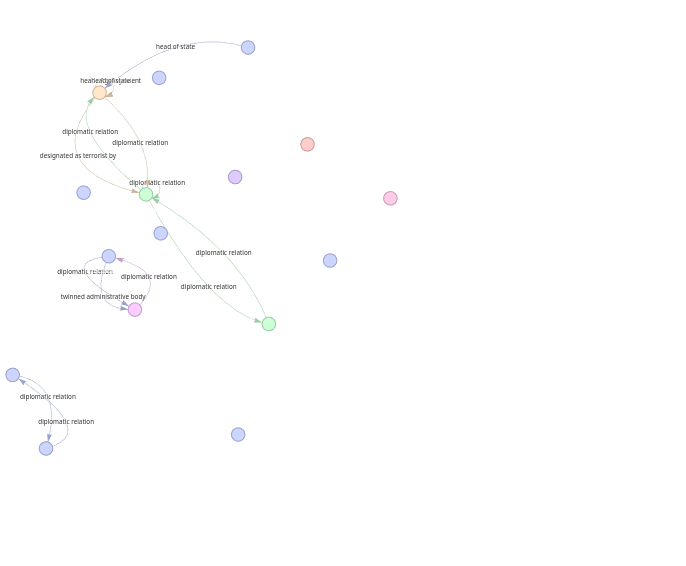
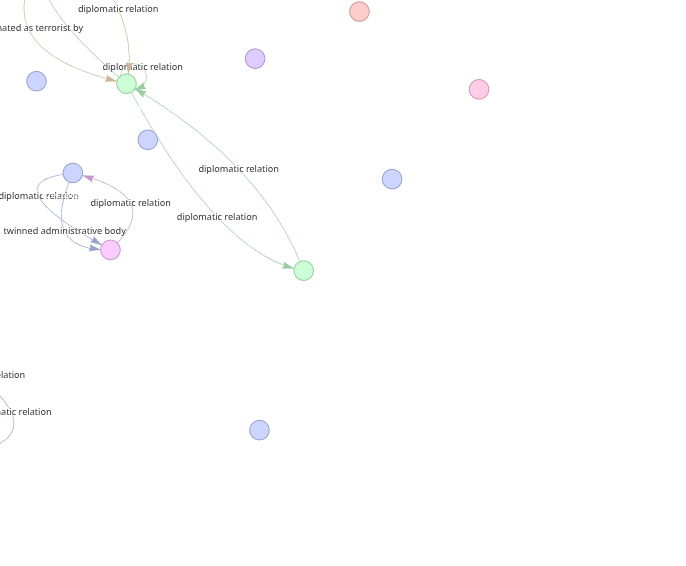
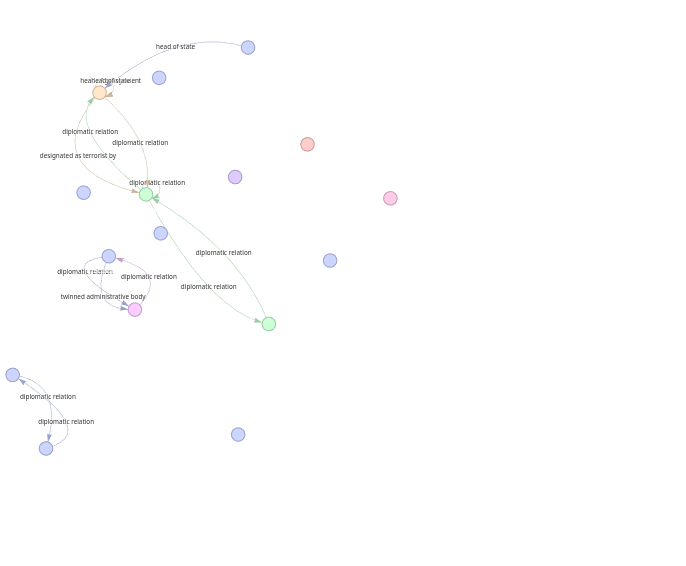
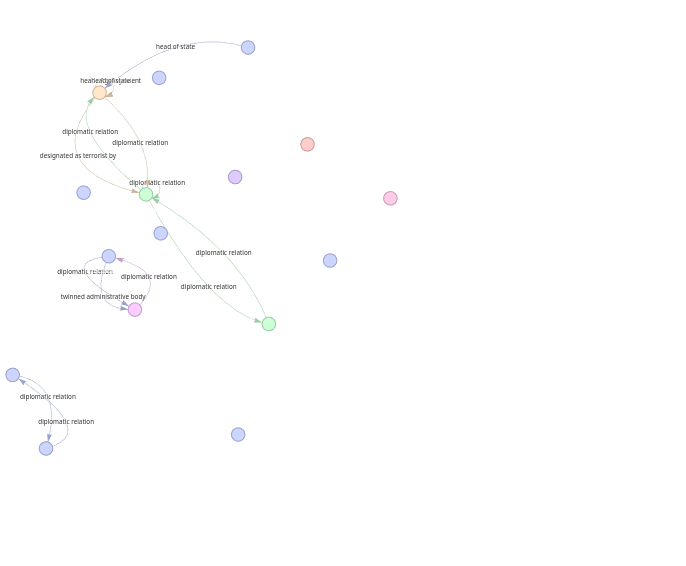

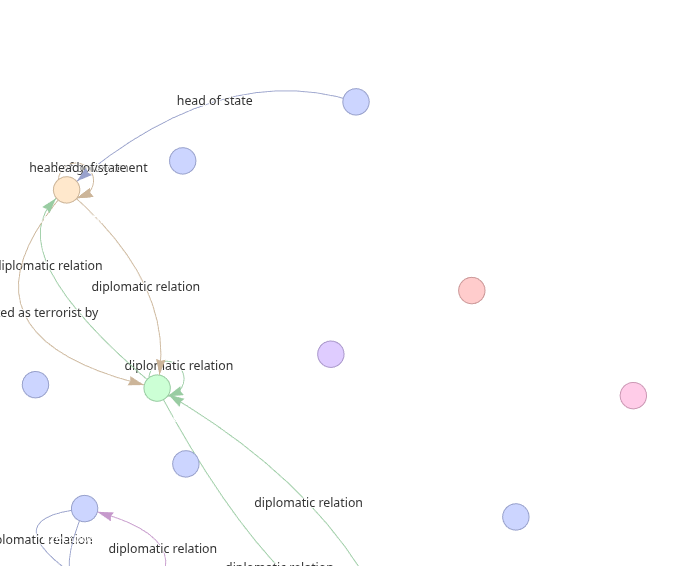